# Correcciones de la Entrega 3: la duración como clasificación

**Proyecto Integrador de Ciencia de Datos · UTN FRM · 2026**
Comisión 5K09 · Grupo 5K09-02

> **La pregunta, reformulada:** sabiendo cómo está la partida al minuto 10,
> ¿en qué banda de 3 minutos va a terminar?

En la Entrega 3 el modelo predecía la duración en segundos (regresión). Por la
corrección del docente, **el problema cambia a clasificación**: el objetivo es la
**banda de 3 minutos** en la que termina la partida, y el modelo es una
**regresión logística**. El grupo la elige por dos razones: es el modelo más simple de
la familia, y **da una probabilidad para cada banda**. Eso es lo que le sirve al
jugador: no «tu partida dura 29 minutos», sino «hay tal probabilidad de que termine
entre los 27 y los 33».

| Corrección del docente | Dónde |
|---|---|
| Cambiar a clasificación, con bandas de 3 minutos y lo que se sabe al minuto 10 | Secciones 1 a 3 |
| Analizar la distribución del error con gráficos | Secciones 4 y 5 |
| Probar el MSE y expresar bien el R² | Sección 7 |

Lo que no cambia: las 137 columnas y el estado al minuto 10, la partición del test
de la E3 (20 %, estratificada por grupo de elo), los cinco pedazos de la validación
cruzada y `SEMILLA = 42`.

# Sección 0 · La base

Las clases que derivan las columnas y la partición son las de la Entrega 3, sin
cambios.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, make_scorer,
                             mean_absolute_error, mean_squared_error, precision_recall_fscore_support,
                             r2_score)
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEMILLA = 42
TEAL, LADRILLO, TEAL_CLARO, GRIS = "#009086", "#B5402C", "#7fc7c2", "#8c8c8c"
POS = ["top", "jng", "mid", "bot", "sup"]
EQUIPOS = ["t1", "t2"]


def buscar(patron, candidatas):
    """El CSV más reciente que cumple el patrón, en la primera carpeta que lo tenga."""
    carpeta = next(c for c in candidatas if any(c.glob(patron)))
    return sorted(carpeta.glob(patron))[-1]


# Los CSV congelados de la E2 y la E3. En Colab, los dos van juntos en datos/
df = pd.read_csv(buscar("lol_2*.csv", [Path("datos"), Path("../entrega-2/datos"), Path("notebooks/entrega-2/datos")]))
min10 = pd.read_csv(buscar("lol_min10_*.csv", [Path("datos"), Path("../entrega-3/datos"), Path("notebooks/entrega-3/datos")]))
pd.Series({"condiciones iniciales": df.shape, "estado al minuto 10": min10.shape})

condiciones iniciales    (19145, 137)
estado al minuto 10       (19008, 35)
dtype: object

In [2]:
# Las columnas derivadas de la Entrega 3, sin cambios
AGG = ["mains_count", "num_tanks", "num_mages", "num_assassins", "num_marksmen", "num_fighters",
       "num_supports", "avg_attack", "avg_defense", "avg_magic", "avg_difficulty", "avg_attackrange",
       "total_base_hp", "total_base_armor", "count_teleport", "count_ignite", "count_flash"]
SUMAS = ["num_tanks", "num_mages", "num_assassins", "num_marksmen", "num_fighters", "num_supports",
         "avg_attack", "avg_difficulty", "avg_attackrange", "total_base_hp", "count_teleport", "count_ignite"]
METRICAS_MINUTO = ["gold", "xp", "cs", "level", "kills", "towers", "elite_monsters"]


def de_jugador(feature, equipos=EQUIPOS):
    """Los nombres de las columnas de una feature de jugador, para los equipos pedidos."""
    return [f"{e}_{p}_{feature}" for e in equipos for p in POS]


def por_equipo(X, equipo):
    """Elo, winrate y log-maestría medios de los cinco jugadores de un equipo."""
    return pd.DataFrame({
        "elo": X[de_jugador("player_elo", [equipo])].mean(axis=1),
        "winrate": X[de_jugador("player_winrate", [equipo])].mean(axis=1),
        "logmastery": np.log1p(X[de_jugador("champ_mastery_pts", [equipo])]).mean(axis=1)}, index=X.index)


class DiferenciasEntreEquipos(BaseEstimator, TransformerMixin):
    """Cuánto se separan los dos equipos en cada columna conocida antes de jugar: |t1 - t2|."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        t1, t2 = por_equipo(X, "t1"), por_equipo(X, "t2")
        nuevas = {f"dif_{a}": (X[f"t1_{a}"] - X[f"t2_{a}"]).abs() for a in AGG}
        nuevas |= {f"dif_{k}": (t1[k] - t2[k]).abs() for k in t1.columns}
        return pd.DataFrame(nuevas, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"dif_{a}" for a in AGG] + ["dif_elo", "dif_winrate", "dif_logmastery"])


class ColumnasDePartida(BaseEstimator, TransformerMixin):
    """Las columnas por partida que dejó la tabla de candidatas de la Entrega 2."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        nuevas = pd.DataFrame({f"suma_{a}": X[f"t1_{a}"] + X[f"t2_{a}"] for a in SUMAS}, index=X.index)
        nuevas["elo_partida"] = X[de_jugador("player_elo")].mean(axis=1)
        nuevas["logmastery_partida"] = np.log1p(X[de_jugador("champ_mastery_pts")]).mean(axis=1)
        nuevas["plataforma"] = X["match_id"].str.split("_").str[0]
        return nuevas

    def get_feature_names_out(self, input_features=None):
        return np.array([f"suma_{a}" for a in SUMAS] + ["elo_partida", "logmastery_partida", "plataforma"])


class EstadoAlMinuto(BaseEstimator, TransformerMixin):
    """Del CSV del minuto N: cuánto se separan los equipos (|t1 - t2|) y el total de la partida (t1 + t2)."""

    def __init__(self, minuto=10):
        self.minuto = minuto

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        s = f"_m{self.minuto}"
        nuevas = {f"suma_{m}{s}": X[f"t1_{m}{s}"] + X[f"t2_{m}{s}"] for m in METRICAS_MINUTO}
        nuevas |= {f"dif_{m}{s}": X[f"dif_{m}{s}"] for m in METRICAS_MINUTO}
        return pd.DataFrame(nuevas, index=X.index)

    def get_feature_names_out(self, input_features=None):
        s = f"_m{self.minuto}"
        return np.array([f"suma_{m}{s}" for m in METRICAS_MINUTO] + [f"dif_{m}{s}" for m in METRICAS_MINUTO])


def armar(modelo):
    """El pipeline de la E3 con el minuto 10: derivar, imputar y escalar, codificar, y el modelo al final."""
    derivar = FeatureUnion([("partida", ColumnasDePartida()), ("diferencias", DiferenciasEntreEquipos()),
                            ("minuto", EstadoAlMinuto(10))],
                           verbose_feature_names_out=False).set_output(transform="pandas")
    preparar = ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]),
         make_column_selector(dtype_include="number")),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_exclude="number"))],
        verbose_feature_names_out=False)
    return Pipeline([("derivar", derivar), ("preparar", preparar), ("modelo", modelo)])

In [3]:
# La partición de la E3: 20 % de test estratificado por grupo de elo, y fuera las 137 partidas que no llegan al minuto 10
GRUPOS = ["Hierro–Oro", "Platino–Diamante", "Master–Challenger"]
grupo = pd.cut(df[de_jugador("player_elo")].mean(axis=1), [-np.inf, 2000, 2900, np.inf], right=False, labels=GRUPOS)
X_train, X_test = train_test_split(df.drop(columns=["game_duration_s"]), test_size=0.2,
                                   stratify=grupo, random_state=SEMILLA)

d10 = df.join(min10.drop(columns="game_duration_s").set_index("match_id"), on="match_id", how="inner")
tr, te = X_train.index.intersection(d10.index), X_test.index.intersection(d10.index)
X10, y10 = d10.loc[tr].drop(columns="game_duration_s"), d10.loc[tr, "game_duration_s"]
X10_te, y10_te = d10.loc[te].drop(columns="game_duration_s"), d10.loc[te, "game_duration_s"]
grupo_te = grupo.loc[te]
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pd.Series({"partidas que llegan al minuto 10": len(d10), "train": len(X10), "test": len(X10_te)})

partidas que llegan al minuto 10    19008
train                               15210
test                                 3798
dtype: int64

# Sección 1 · El objetivo nuevo: la banda de 3 minutos

Doce bandas: de 3 minutos entre los 15 y los 45, y dos abiertas en las puntas,
**`<15`** y **`45+`**, porque de 54 minutos en adelante quedan entre 1 y 7 partidas por
banda. Cada banda incluye su borde inferior (`15-18` es de 15:00 a 17:59).

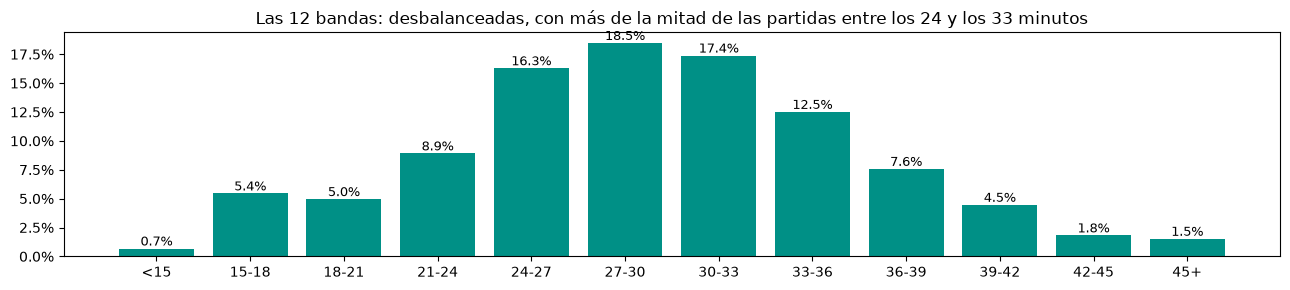

In [4]:
CORTES = [0, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, np.inf]
BANDAS = ["<15", "15-18", "18-21", "21-24", "24-27", "27-30", "30-33", "33-36", "36-39", "39-42", "42-45", "45+"]
K = len(BANDAS)


def banda_de(segundos):
    """El número de banda (0 = <15 … 11 = 45+) de una duración en segundos."""
    return pd.cut(segundos / 60, CORTES, right=False, labels=False).astype(int)


yb, yb_te = banda_de(y10), banda_de(y10_te)
# El minuto que representa a cada banda: la mediana de la duración de sus partidas de entrenamiento
MINUTO = (y10.groupby(yb).median() / 60).reindex(range(K)).to_numpy()

proporcion = pd.concat([yb, yb_te]).value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(BANDAS, proporcion, color=TEAL)
for i, v in enumerate(proporcion):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Las 12 bandas: desbalanceadas, con más de la mitad de las partidas entre los 24 y los 33 minutos")
plt.tight_layout()
plt.show()

**Las bandas están desbalanceadas.** Las tres del centro —`24-27`, `27-30` y `30-33`—
juntan el **52 %** de las partidas; `<15` tiene el **0,7 %** y `45+`, el 1,5 %. Un
modelo que conteste siempre el centro acierta mucho sin saber nada. Por eso el piso
se mide, y por eso decide el F1 macro.

# Sección 2 · Elegir el modelo

**Las métricas.** Decide el **F1 macro** (Práctica 2): el F1 de cada banda,
promediado sin pesar, así que una banda chica cuenta igual que una grande. Al lado:
la **accuracy** (banda exacta) y el **acierto a ±1 banda** (la correcta o una vecina,
unos ±3 minutos), que agrega el grupo porque es la lectura del jugador.

**Los modelos.** El piso, `DummyClassifier(strategy="prior")`, contesta siempre la
banda más frecuente, y como probabilidades da la frecuencia de cada banda en el
entrenamiento, iguales para todas las partidas. La regresión logística va en dos versiones: **sin pesos**, y con
**`class_weight="balanced"`**, que pesa cada partida por la inversa de la frecuencia
de su banda (Práctica 2, Parte 6). En las dos se ajusta `C`, la inversa de la
regularización: **más chico, más regularizado**.

In [5]:
def a_una_banda(real, pred):
    """Proporción de partidas cuya banda predicha está a lo sumo a una de la real."""
    return np.mean(np.abs(np.asarray(real) - np.asarray(pred)) <= 1)


SCORERS = {"F1 macro": "f1_macro", "accuracy": "accuracy", "±1 banda": make_scorer(a_una_banda)}
VERSIONES = {"logística sin pesos": None, "logística balanced": "balanced"}
GRILLA_C = [0.001, 0.01, 0.1, 1, 10]

piso = cross_validate(armar(DummyClassifier(strategy="prior")), X10, yb, cv=cv, scoring=SCORERS,
                      return_train_score=True, n_jobs=-1)
busquedas = {n: GridSearchCV(armar(LogisticRegression(max_iter=3000, class_weight=pesos)),
                             {"modelo__C": GRILLA_C}, cv=cv, scoring=SCORERS, refit="F1 macro",
                             return_train_score=True, n_jobs=-1).fit(X10, yb)
             for n, pesos in VERSIONES.items()}
modelos = {n: b.best_estimator_ for n, b in busquedas.items()}

filas = {"piso (banda más frecuente)": {f"{m} cv": piso[f"test_{m}"].mean() for m in SCORERS} |
                                       {"desvío F1": piso["test_F1 macro"].std(), "C": np.nan}}
for n, b in busquedas.items():
    i = b.best_index_
    filas[n] = {f"{m} cv": b.cv_results_[f"mean_test_{m}"][i] for m in SCORERS} | \
               {"desvío F1": b.cv_results_["std_test_F1 macro"][i], "C": b.best_params_["modelo__C"]}
tabla = pd.DataFrame(filas).T[["C", "F1 macro cv", "desvío F1", "accuracy cv", "±1 banda cv"]]
tabla.round(3)

,C,F1 macro cv,desvío F1,accuracy cv,±1 banda cv
piso (banda más frecuente),NaN,0.026,0.001,0.186,0.521
logística sin pesos,1.0,0.106,0.005,0.198,0.532
logística balanced,0.1,0.101,0.008,0.105,0.286


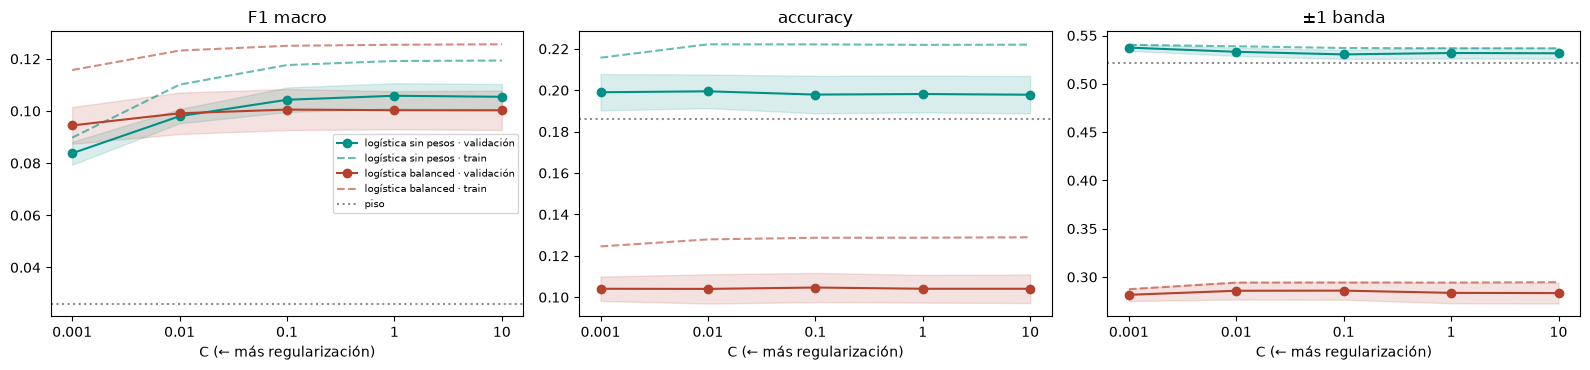

In [6]:
# La curva de C (Práctica 2, Parte 3.3): F1 macro en train y en validación, para las dos versiones
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, metrica in zip(axes, SCORERS):
    for (n, b), color in zip(busquedas.items(), [TEAL, LADRILLO]):
        r = b.cv_results_
        ax.plot([str(c) for c in GRILLA_C], r[f"mean_test_{metrica}"], marker="o", color=color, label=f"{n} · validación")
        ax.fill_between([str(c) for c in GRILLA_C], r[f"mean_test_{metrica}"] - r[f"std_test_{metrica}"],
                        r[f"mean_test_{metrica}"] + r[f"std_test_{metrica}"], color=color, alpha=0.15)
        ax.plot([str(c) for c in GRILLA_C], r[f"mean_train_{metrica}"], linestyle="--", color=color,
                alpha=0.6, label=f"{n} · train")
    ax.axhline(piso[f"test_{metrica}"].mean(), color=GRIS, linestyle=":", label="piso")
    ax.set_xlabel("C (← más regularización)")
    ax.set_title(metrica)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

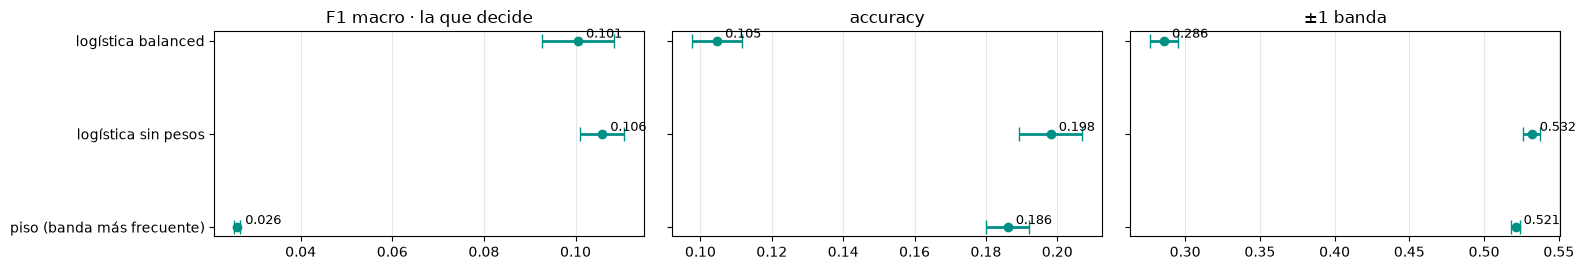

In [7]:
# La comparación con barra de error (Práctica 2, Parte 2.2): media ± desvío entre los cinco pedazos
fig, axes = plt.subplots(1, 3, figsize=(16, 2.8), sharey=True)
desvios = {"piso (banda más frecuente)": {m: piso[f"test_{m}"].std() for m in SCORERS}} | \
          {n: {m: b.cv_results_[f"std_test_{m}"][b.best_index_] for m in SCORERS} for n, b in busquedas.items()}
for ax, metrica in zip(axes, SCORERS):
    medias = tabla[f"{metrica} cv"]
    ax.errorbar(medias, medias.index, xerr=[desvios[n][metrica] for n in medias.index], fmt="o",
                color=TEAL, ecolor=TEAL, elinewidth=2, capsize=5)
    for n, v in medias.items():
        ax.text(v, n, f"  {v:.3f}", va="bottom", fontsize=9)
    ax.set_title(metrica + (" · la que decide" if metrica == "F1 macro" else ""))
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Las dos versiones empatan en F1 macro, y en todo lo demás gana la sin pesos.**

- **Sin pesos** (`C=1`): F1 macro **0,106 ± 0,005**, accuracy 19,8 % y ±1 banda 53,2 %.
- **Balanced** (`C=0,1`): F1 macro **0,101 ± 0,008**, accuracy **10,5 %** y ±1 banda
  **28,6 %**. Las dos últimas, muy por debajo del piso.
- **Piso**: F1 macro 0,026, accuracy 18,6 % y ±1 banda 52,1 %.

**La regla de la cátedra elige la logística sin pesos**: los pesos no le ganan por más
que su desvío, de hecho dan 0,005 menos. Es el caso de la Práctica 2: `balanced` hace
que el modelo conteste las bandas chicas, pero las contesta mal, y pierde las grandes.

**La curva de C** dice que la regularización casi no importa: entre `C=0,01` y `C=10`
las curvas son planas, y sólo con `C=0,001` el F1 de la sin pesos cae a 0,084. La
distancia entre train y validación es chica (0,013 en F1 la sin pesos): **no
sobreajusta**.

# Sección 3 · El test, una sola vez

Además de las métricas de clasificación, se mide el error **en minutos**: cada
banda se representa con la mediana de la duración de sus partidas de entrenamiento,
y se cuenta en qué porcentaje de las partidas la banda predicha queda a menos de 3 y
de 5 minutos de lo real.

In [8]:
piso_final = armar(DummyClassifier(strategy="prior")).fit(X10, yb)
pred = {"piso (banda más frecuente)": pd.Series(piso_final.predict(X10_te), index=te)} | \
       {n: pd.Series(m.predict(X10_te), index=te) for n, m in modelos.items()}
proba = {n: pd.DataFrame(m.predict_proba(X10_te), index=te, columns=BANDAS) for n, m in modelos.items()}
error_min = {n: pd.Series(MINUTO[p], index=te) - y10_te / 60 for n, p in pred.items()}


def metricas(real, p, n):
    """Las métricas de clasificación y las del error en minutos."""
    e = error_min[n].loc[real.index].abs()
    return {"F1 macro": f1_score(real, p, average="macro", labels=range(K), zero_division=0),
            "accuracy": accuracy_score(real, p), "±1 banda": a_una_banda(real, p),
            "error ≤ 3 min": (e <= 3).mean(), "error ≤ 5 min": (e <= 5).mean(), "error medio (min)": e.mean()}


test = pd.DataFrame({n: metricas(yb_te, p, n) for n, p in pred.items()}).T
test.round(3)

,F1 macro,accuracy,±1 banda,error ≤ 3 min,error ≤ 5 min,error medio (min)
piso (banda más frecuente),0.025,0.179,0.522,0.37,0.570,5.326
logística sin pesos,0.099,0.197,0.525,0.38,0.572,5.261
logística balanced,0.096,0.101,0.277,0.18,0.301,10.071


**En el test, la logística sin pesos da F1 macro 0,099, accuracy 19,7 % y ±1 banda
52,5 %**; el piso, 0,025, 17,9 % y 52,2 %. El F1 queda un poco por debajo de la
validación (0,106), en línea con ella.

**Hay que decirlo con todas las letras: en minutos, la logística casi no le gana al
piso.** Con la sin pesos, el **38,0 %** de las partidas queda a menos de 3 minutos de lo
real, contra el **37,0 %** del piso; a menos de 5 minutos, 57,2 % contra 57,0 %. La
balanced queda muy abajo: 18,0 % y un error medio de **10,1 minutos**, el doble que el
piso. Lo que la logística agrega no está en la banda que contesta, sino en las
**probabilidades** (Sección 5).

# Sección 4 · Dónde se equivoca

El análisis del error, como en la Práctica 1 (4.3, «la accuracy no alcanza»): la
matriz de confusión, las métricas de cada banda, el error en bandas y el error por
grupo de elo.

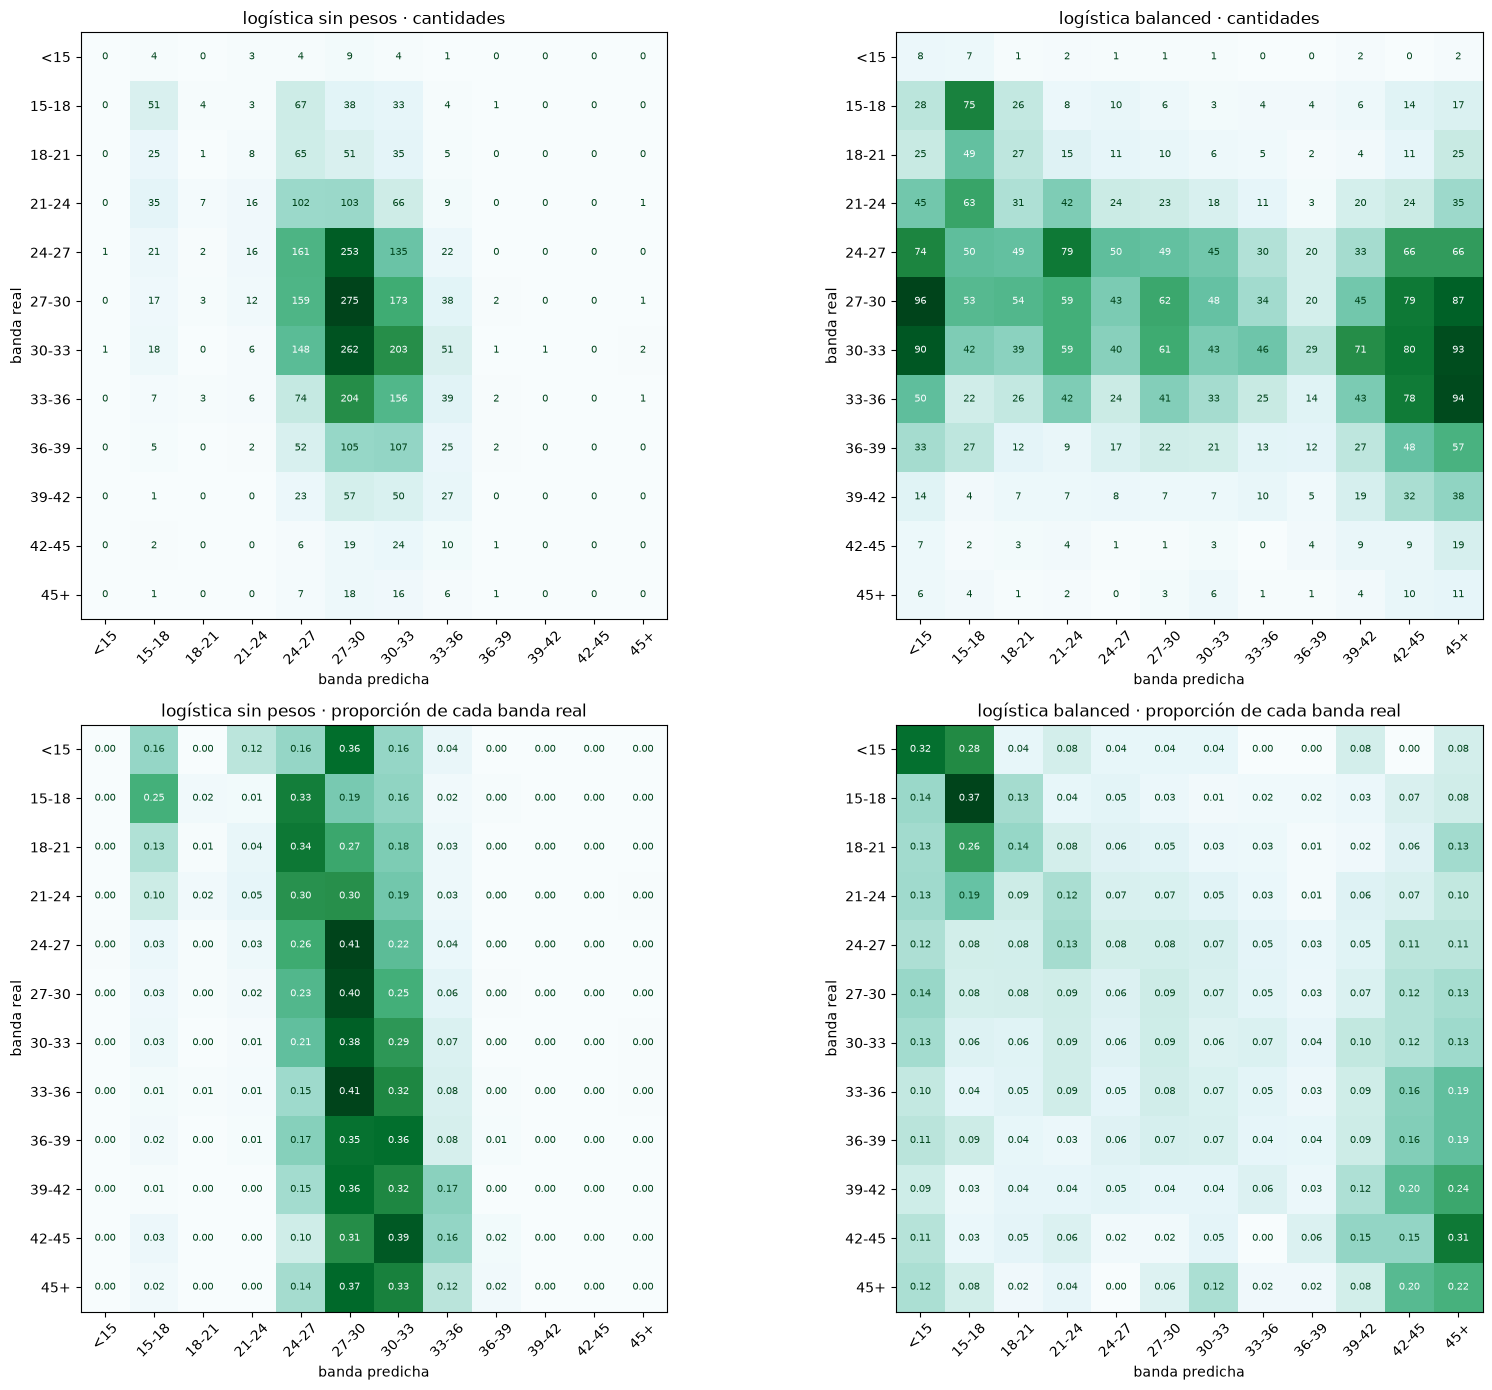

In [9]:
# 4.1 · Las matrices de confusión: cantidades arriba, y normalizadas por fila abajo (de cada banda real, a dónde va)
fig, axes = plt.subplots(2, 2, figsize=(17, 14))
for col, n in enumerate(modelos):
    for fila, (normalizar, formato) in enumerate([(None, "d"), ("true", ".2f")]):
        ax = axes[fila, col]
        ConfusionMatrixDisplay.from_predictions(yb_te, pred[n], labels=range(K), display_labels=BANDAS,
                                                normalize=normalizar, values_format=formato, cmap="BuGn",
                                                colorbar=False, ax=ax, text_kw={"fontsize": 7})
        ax.set_title(f"{n} · {'cantidades' if normalizar is None else 'proporción de cada banda real'}")
        ax.set_xlabel("banda predicha")
        ax.set_ylabel("banda real")
        ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**La sin pesos contesta casi siempre el centro.** Las columnas de la matriz se juntan
en `24-27`, `27-30` y `30-33`: en todas las filas, de `<15` a `45+`, entre el 68 y el
89 % de las partidas cae ahí. **Nunca contesta `<15`, `39-42` ni `42-45`**, y `45+`
sólo cinco veces, todas mal. La única banda fuera del centro que contesta con algún
acierto es `15-18`: 51 de sus 201 partidas, el 25 %.

**La balanced se reparte por toda la matriz.** Acierta el 32 % de las partidas de `<15`
y el 22 % de las de `45+`, pero para eso contesta esas bandas cientos de veces: 96
partidas de `27-30` terminan predichas como `<15`. Es una matriz sin diagonal.

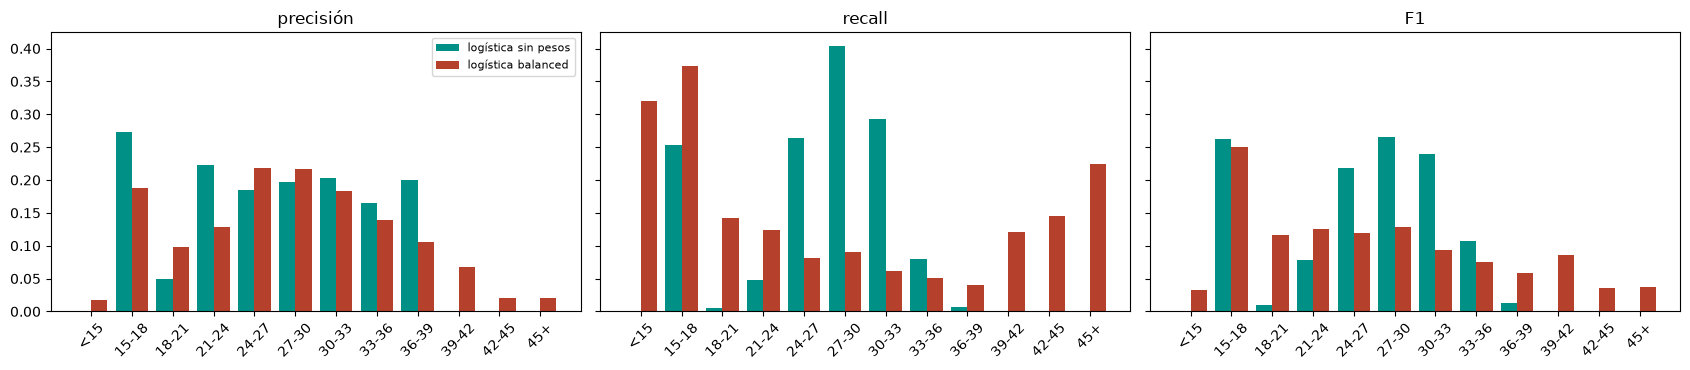

logística sin pesos                       logística balanced                      
                precisión recall    F1 partidas          precisión recall    F1 partidas
<15                  0.00   0.00  0.00       25               0.02   0.32  0.03       25
15-18                0.27   0.25  0.26      201               0.19   0.37  0.25      201
18-21                0.05   0.01  0.01      190               0.10   0.14  0.12      190
21-24                0.22   0.05  0.08      339               0.13   0.12  0.13      339
24-27                0.19   0.26  0.22      611               0.22   0.08  0.12      611
27-30                0.20   0.40  0.27      680               0.22   0.09  0.13      680
30-33                0.20   0.29  0.24      693               0.18   0.06  0.09      693
33-36                0.16   0.08  0.11      492               0.14   0.05  0.07      492
36-39                0.20   0.01  0.01      298               0.11   0.04  0.06      298
39-42                0.00   0.00  0.00      158               0.07   0.12  0.09      158
42-45                0.00   0.00  0.00       62               0.02   0.15  0.04       62
45+                  0.00   0.00  0.00       49               0.02   0.22  0.04       49

In [10]:
# 4.2 · Precisión, recall y F1 de cada banda (el classification_report, dibujado)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
reporte = {}
for n, color, desp in zip(modelos, [TEAL, LADRILLO], [-0.2, 0.2]):
    p, r, f, s = precision_recall_fscore_support(yb_te, pred[n], labels=range(K), zero_division=0)
    reporte[n] = pd.DataFrame({"precisión": p, "recall": r, "F1": f, "partidas": s}, index=BANDAS)
    for ax, m in zip(axes, ["precisión", "recall", "F1"]):
        ax.bar(np.arange(K) + desp, reporte[n][m], 0.4, color=color, label=n)
for ax, m in zip(axes, ["precisión", "recall", "F1"]):
    ax.set_xticks(range(K), BANDAS, rotation=45)
    ax.set_title(m)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.concat(reporte, axis=1).round(2)

**Por banda, la sin pesos sólo funciona en el centro y en `15-18`.** Su mejor F1 está
en `27-30` (0,27), `15-18` (0,26), `30-33` (0,24) y `24-27` (0,22). En `<15`, `39-42`,
`42-45` y `45+` el F1 es cero.

**La balanced cambia recall por precisión.** Sube el recall de las puntas (`<15`, de 0
a 0,32; `45+`, de 0 a 0,22), pero con una precisión de 0,02: de cada cincuenta veces
que dice `45+`, acierta una. Y en el centro el recall se derrumba: en `27-30`, de 0,40
a 0,09.

**`15-18` es la banda que se ve venir.** Es el escalón de la rendición (Entrega 2): con
una ventaja grande al minuto 10, el equipo que va perdiendo suele rendirse apenas se
habilita la votación, en el minuto 15.

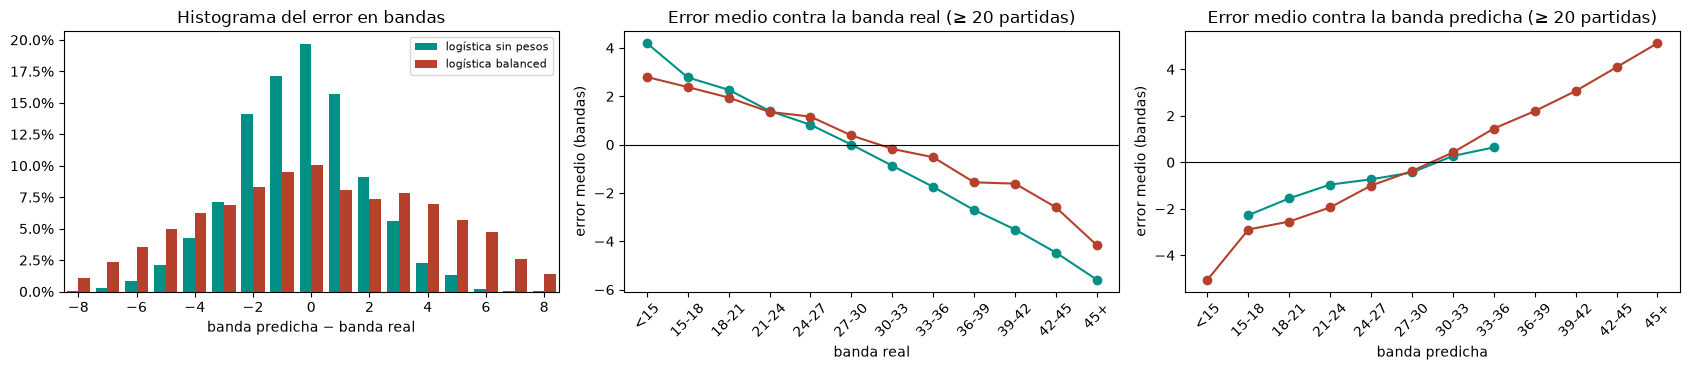

,banda exacta,a 1 banda,a 2 bandas,a 3 o más,error medio (bandas)
logística sin pesos,0.197,0.328,0.232,0.243,-0.345
logística balanced,0.101,0.176,0.157,0.566,0.232


In [11]:
# 4.3 · El error en bandas (predicha − real): su histograma, y su media contra la banda real y contra la predicha
error_banda = {n: pred[n] - yb_te for n in modelos}
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for (n, e), color, desp in zip(error_banda.items(), [TEAL, LADRILLO], [-0.2, 0.2]):
    frec = e.value_counts(normalize=True).reindex(range(-K + 1, K), fill_value=0)
    axes[0].bar(frec.index + desp, frec, 0.4, color=color, label=n)
    for ax, ref in zip(axes[1:], [yb_te, pred[n]]):
        medio = e.groupby(ref).agg(["mean", "size"])
        medio = medio[medio["size"] >= 20]
        ax.plot(medio.index, medio["mean"], marker="o", color=color, label=n)
axes[0].set_xlim(-8.5, 8.5)
axes[0].set_xlabel("banda predicha − banda real")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_title("Histograma del error en bandas")
axes[0].legend(fontsize=8)
for ax, eje in zip(axes[1:], ["real", "predicha"]):
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(f"banda {eje}")
    ax.set_ylabel("error medio (bandas)")
    ax.set_title(f"Error medio contra la banda {eje} (≥ 20 partidas)")
    ax.set_xticks(range(K), BANDAS, rotation=45)
plt.tight_layout()
plt.show()
pd.DataFrame({n: {"banda exacta": (e == 0).mean(), "a 1 banda": (e.abs() == 1).mean(),
                  "a 2 bandas": (e.abs() == 2).mean(), "a 3 o más": (e.abs() >= 3).mean(),
                  "error medio (bandas)": e.mean()} for n, e in error_banda.items()}).T.round(3)

**La sin pesos erra cerca.** Acierta la banda exacta en el **19,7 %** de las partidas y
queda a una banda en el **32,8 %**: más de la mitad a un paso o menos. A tres bandas o
más, el 24,3 %. La balanced, 10,1 % exacta y **56,6 % a tres bandas o más**.

**Contra la banda real, el error es una recta que baja**: la sin pesos predice las
partidas de `<15` unas cuatro bandas más largas, y las de `45+`, casi seis más cortas.
Es la tendencia al centro de un modelo con poca señal. **Contra la banda predicha,
la sin pesos queda cerca de cero en el centro**: cuando dice `27-30`, termina en
promedio ahí. La balanced se aleja en las puntas: cuando dice `45+`, la partida
termina en promedio unas cinco bandas antes.

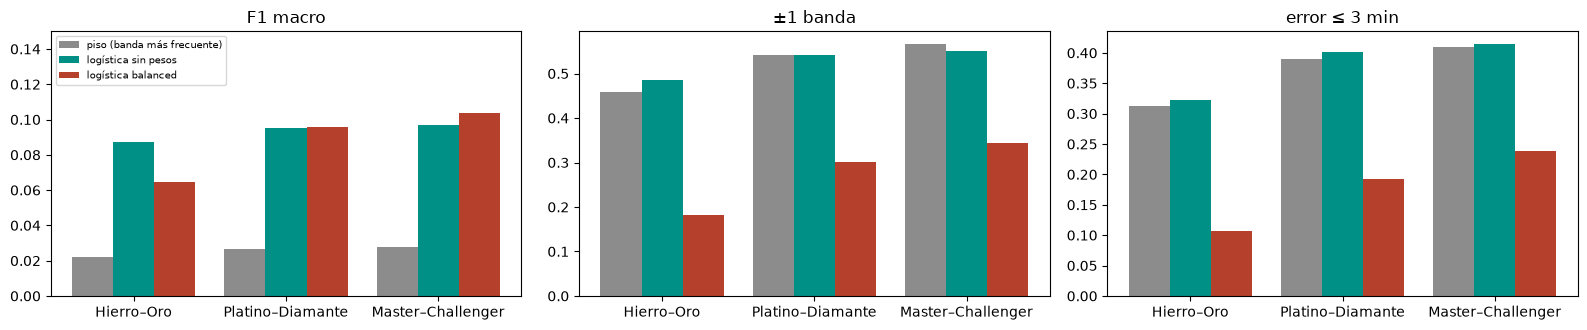

F1 macro  accuracy  ±1 banda  error ≤ 3 min
Hierro–Oro        piso (banda más frecuente)     0.022     0.151     0.457          0.312
                  logística sin pesos            0.087     0.165     0.485          0.323
                  logística balanced             0.065     0.065     0.182          0.107
Platino–Diamante  piso (banda más frecuente)     0.027     0.189     0.543          0.389
                  logística sin pesos            0.095     0.206     0.542          0.402
                  logística balanced             0.096     0.104     0.302          0.193
Master–Challenger piso (banda más frecuente)     0.027     0.197     0.567          0.409
                  logística sin pesos            0.097     0.220     0.550          0.415
                  logística balanced             0.104     0.132     0.344          0.238

In [12]:
# 4.4 · Por grupo de elo
por_grupo = pd.concat({g: pd.DataFrame({n: metricas(yb_te[grupo_te == g], p[grupo_te == g], n)
                                        for n, p in pred.items()}).T for g in GRUPOS})
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), sharey=False)
for ax, m in zip(axes, ["F1 macro", "±1 banda", "error ≤ 3 min"]):
    for i, (n, color) in enumerate(zip(pred, [GRIS, TEAL, LADRILLO])):
        ax.bar(np.arange(3) + (i - 1) * 0.27, [por_grupo.loc[(g, n), m] for g in GRUPOS], 0.27, color=color, label=n)
    ax.set_xticks(range(3), GRUPOS)
    ax.set_title(m)
axes[0].set_ylim(0, 0.15)
axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()
por_grupo[["F1 macro", "accuracy", "±1 banda", "error ≤ 3 min"]].round(3)

**Por grupo de elo, la sin pesos ayuda donde el piso más falla.** En Hierro–Oro, el
acierto a ±1 banda pasa de 45,7 % (piso) a **48,5 %**, y a menos de 3 minutos, de 31,2 a
32,3 %. En Platino–Diamante empata con el piso (54,2 contra 54,3 %), y en
Master–Challenger queda apenas debajo en ±1 banda (55,0 contra 56,7 %). La balanced
queda lejos en los tres grupos.

# Sección 5 · Lo que le sirve al jugador

La razón para elegir la logística es que da **una probabilidad para cada banda**.
Eso sirve sólo si las probabilidades son **creíbles**: si cuando el modelo dice 60 %,
pasa más o menos el 60 % de las veces. Esta sección lo mide.

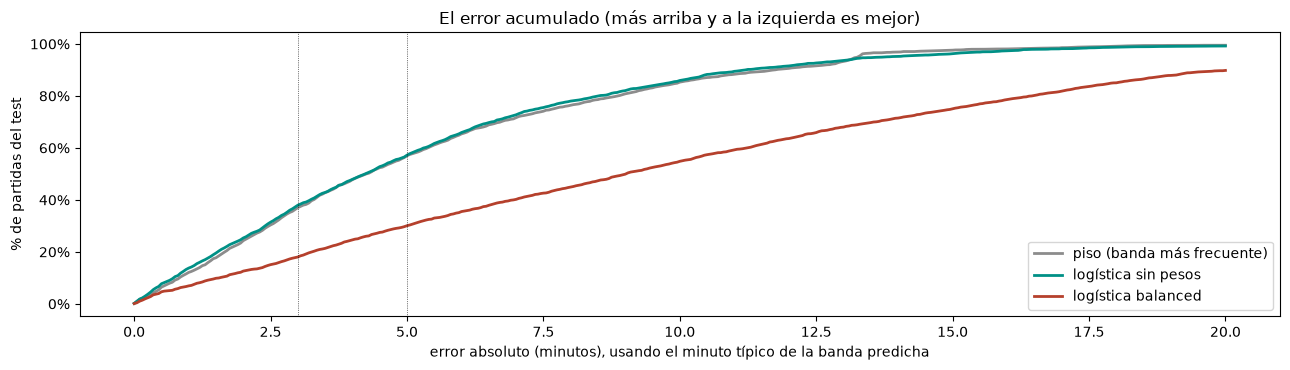

In [13]:
# 5.1 · El error acumulado en minutos: qué porcentaje de las partidas queda a menos de t minutos de lo real
t = np.linspace(0, 20, 401)
fig, ax = plt.subplots(figsize=(13, 3.8))
for (n, e), color in zip(error_min.items(), [GRIS, TEAL, LADRILLO]):
    ax.plot(t, [(e.abs() <= u).mean() for u in t], color=color, linewidth=2, label=n)
for u in [3, 5]:
    ax.axvline(u, color="black", linewidth=0.5, linestyle=":")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("error absoluto (minutos), usando el minuto típico de la banda predicha")
ax.set_ylabel("% de partidas del test")
ax.set_title("El error acumulado (más arriba y a la izquierda es mejor)")
ax.legend()
plt.tight_layout()
plt.show()

**Las curvas de la sin pesos y del piso casi se superponen**, y la de la balanced queda
muy abajo. Contestar una sola banda, en minutos, no es mejor que contestar siempre el
centro. Por eso la utilidad hay que buscarla en las probabilidades.

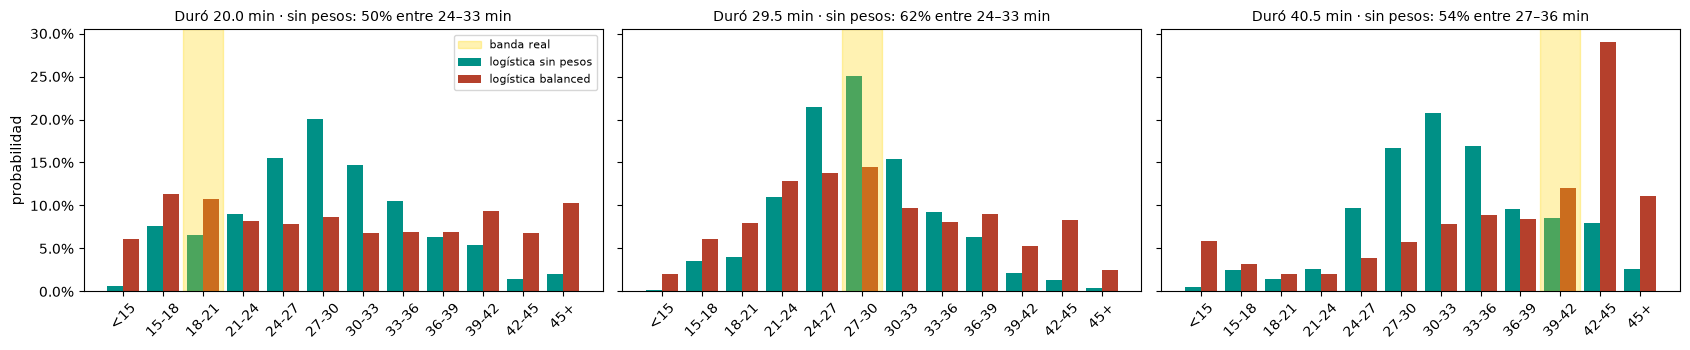

In [14]:
# 5.2 · Lo que vería el jugador: las probabilidades por banda de tres partidas del test, una corta, una media y una larga
def ventana(p):
    """Las tres bandas consecutivas más probables y su probabilidad sumada."""
    sumas = [p.iloc[i:i + 3].sum() for i in range(K - 2)]
    i = int(np.argmax(sumas))
    return f"{BANDAS[i].split('-')[0]}–{BANDAS[i + 2].split('-')[-1]} min", sumas[i]


ejemplos = [yb_te[yb_te == b].sample(1, random_state=SEMILLA).index[0] for b in [2, 5, 9]]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
for ax, i in zip(axes, ejemplos):
    for n, color, desp in zip(modelos, [TEAL, LADRILLO], [-0.2, 0.2]):
        ax.bar(np.arange(K) + desp, proba[n].loc[i], 0.4, color=color, label=n)
    ax.axvspan(yb_te[i] - 0.5, yb_te[i] + 0.5, color="gold", alpha=0.3, label="banda real")
    rango, prob = ventana(proba["logística sin pesos"].loc[i])
    ax.set_title(f"Duró {y10_te[i] / 60:.1f} min · sin pesos: {prob:.0%} entre {rango}", fontsize=10)
    ax.set_xticks(range(K), BANDAS, rotation=45)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_ylabel("probabilidad")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Así se lee lo que vería el jugador.** La barra amarilla es la banda real.

- **La partida de 29,5 minutos**: la sin pesos le da un **62 % a la ventana de 24 a 33
  minutos**, y la banda más probable, `27-30`, es la real.
- **La de 20 minutos**: da un 50 % a la ventana de 24 a 33. Falla, y avisa que no está
  segura: la mitad de la probabilidad queda afuera.
- **La de 40,5 minutos**: da un 54 % a la ventana de 27 a 36. También falla, porque a la
  banda real le da un 8,5 %.

La balanced reparte más la probabilidad: en la partida larga pone un 29 % en `42-45`,
más cerca de lo real, pero lo mismo hace en partidas que no son largas (Sección 4).

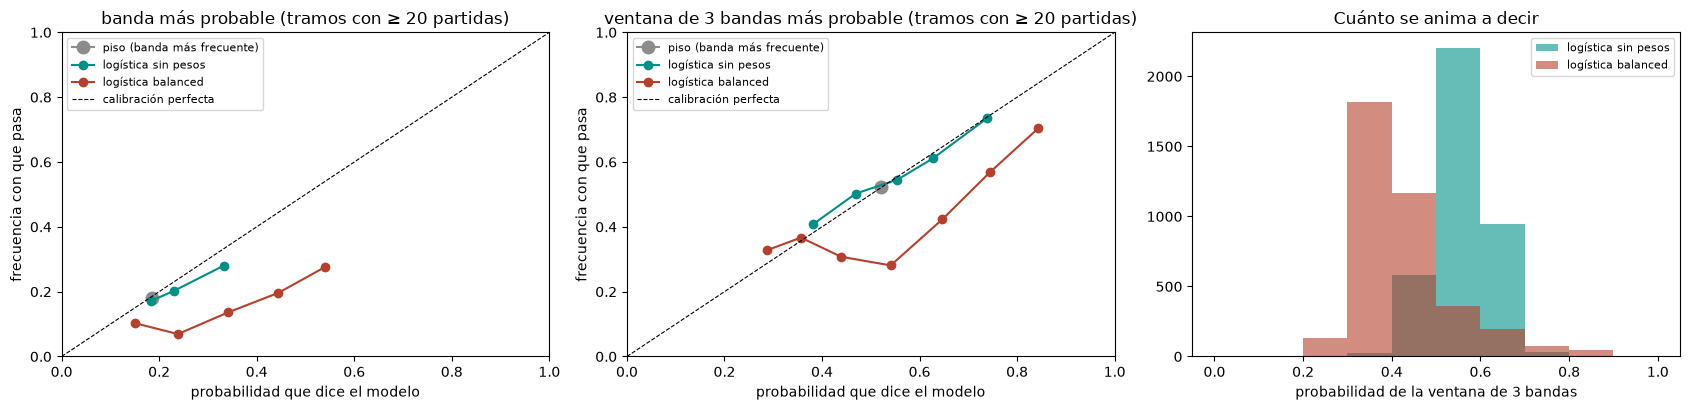

probabilidad media que dice  frecuencia con que pasa
piso (banda más frecuente) banda más probable                                      0.186                    0.179
                           ventana de 3 bandas más probable                        0.521                    0.522
logística sin pesos        banda más probable                                      0.220                    0.197
                           ventana de 3 bandas más probable                        0.561                    0.556
logística balanced         banda más probable                                      0.188                    0.101
                           ventana de 3 bandas más probable                        0.426                    0.350

In [15]:
# 5.3 · La calibración: cuando el modelo dice «p %», ¿pasa el p % de las veces?
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
cortes = np.linspace(0, 1, 11)
calibracion, resolucion = {}, {}
# El piso también da probabilidades: las frecuencias de cada banda en el entrenamiento, iguales para todas las partidas
probas = {"piso (banda más frecuente)": piso_final.predict_proba(X10_te)} | {n: p.to_numpy() for n, p in proba.items()}
for n, color in zip(probas, [GRIS, TEAL, LADRILLO]):
    P = probas[n]
    top = P.argmax(axis=1)
    sumas = np.array([[P[j, i:i + 3].sum() for i in range(K - 2)] for j in range(len(P))])
    inicio = sumas.argmax(axis=1)
    casos = {"banda más probable": (P.max(axis=1), top == yb_te.to_numpy()),
             "ventana de 3 bandas más probable": (sumas.max(axis=1),
                                                  (yb_te.to_numpy() >= inicio) & (yb_te.to_numpy() <= inicio + 2))}
    for ax, (caso, (dice, acierta)) in zip(axes[:2], casos.items()):
        tramo = pd.cut(dice, cortes)
        c = pd.DataFrame({"dice": dice, "acierta": acierta}).groupby(tramo, observed=True).agg(
            dice=("dice", "mean"), pasa=("acierta", "mean"), partidas=("acierta", "size"))
        c = c[c["partidas"] >= 20]
        ax.plot(c["dice"], c["pasa"], marker="o", markersize=9 if n.startswith("piso") else 6, color=color, label=n)
        calibracion[(n, caso)] = {"probabilidad media que dice": dice.mean(), "frecuencia con que pasa": acierta.mean()}
    if not n.startswith("piso"):
        axes[2].hist(sumas.max(axis=1), bins=cortes, color=color, alpha=0.6, label=n)
        # La resolución: si el modelo distingue las partidas en las que puede estar seguro de las que no
        dice, acierta = casos["ventana de 3 bandas más probable"]
        for tramo, sel in {"dice menos de 50 %": dice < 0.5, "dice 50–60 %": (dice >= 0.5) & (dice < 0.6),
                           "dice 60 % o más": dice >= 0.6}.items():
            resolucion[(n, tramo)] = {"% de las partidas": sel.mean(), "probabilidad media que dice": dice[sel].mean(),
                                      "frecuencia con que pasa": acierta[sel].mean()}
for ax, caso in zip(axes[:2], ["banda más probable", "ventana de 3 bandas más probable"]):
    ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=0.8, label="calibración perfecta")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("probabilidad que dice el modelo")
    ax.set_ylabel("frecuencia con que pasa")
    ax.set_title(caso + " (tramos con ≥ 20 partidas)")
    ax.legend(fontsize=8)
axes[2].set_xlabel("probabilidad de la ventana de 3 bandas")
axes[2].set_title("Cuánto se anima a decir")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(calibracion).T.round(3)

**Las probabilidades de la ventana de la sin pesos son creíbles.** En promedio dice
**56,1 %** y pasa el **55,6 %** de las veces, y la curva sigue la diagonal entre el 38 y
el 74 %. Para la banda exacta exagera un poco: dice 22,0 % y pasa el 19,7 %. **La
balanced está mal calibrada**: dice 42,6 % y pasa el 35,0 %. Es un efecto conocido de
los pesos: cambian para qué lado se inclina el modelo, y con eso las probabilidades
dejan de ser frecuencias.

**El piso también está calibrado**, pero dice siempre lo mismo: 52 % para la ventana de
24 a 33 minutos, en todas las partidas. Una probabilidad calibrada sirve si **cambia de
partida en partida**, y eso es lo que mide la tabla de resolución.

In [16]:
# La resolución: en qué partidas la ventana de 3 bandas es más segura, y si acierta más ahí
pd.DataFrame(resolucion).T.round(3)

% de las partidas  probabilidad media que dice  frecuencia con que pasa
logística sin pesos dice menos de 50 %              0.160                        0.465                    0.498
                    dice 50–60 %                    0.580                        0.554                    0.545
                    dice 60 % o más                 0.260                        0.633                    0.617
logística balanced  dice menos de 50 %              0.821                        0.385                    0.343
                    dice 50–60 %                    0.096                        0.541                    0.281
                    dice 60 % o más                 0.083                        0.700                    0.502

**La sin pesos distingue partidas en las que puede estar más segura.** En el **26 %** de
las partidas dice 60 % o más para su ventana, y acierta el **61,7 %**. En el 16 % dice
menos de 50 %, y acierta el 49,8 %. El piso dice 52 % siempre. La diferencia no es
grande: va del 50 al 62 %. Pero es real, está calibrada, y es lo único que la
logística le da al jugador que el piso no le da.

# Sección 6 · Qué aprendió

Como en la Práctica 1 (5.1 y 5.4): los coeficientes de la logística, que dicen qué
empuja hacia cada banda, y la importancia por permutación, que dice qué columnas
necesita el modelo.

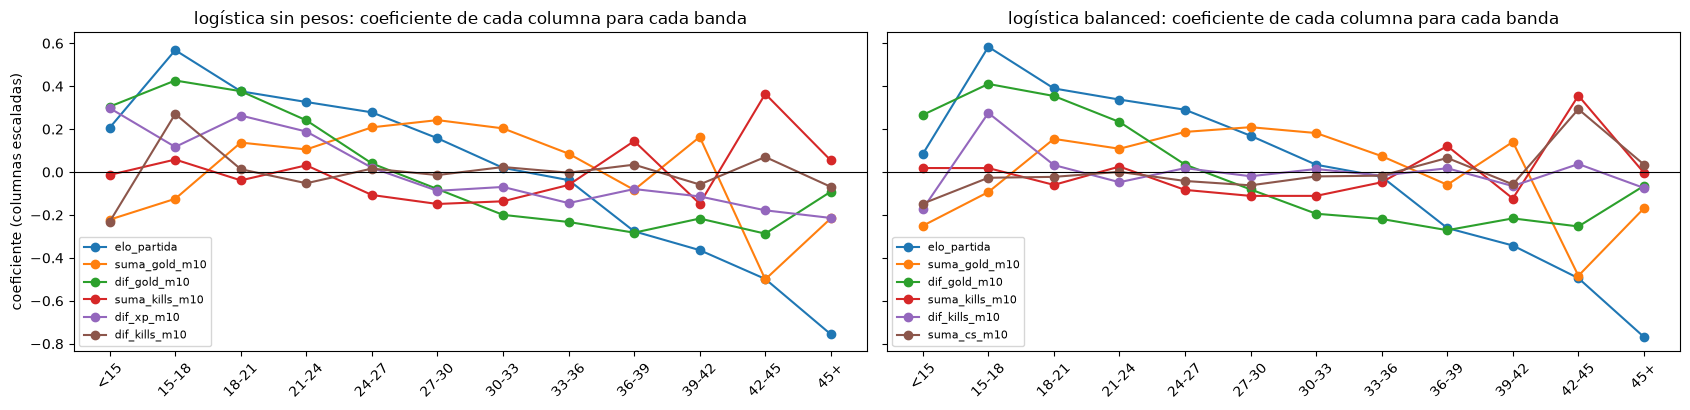

In [17]:
# 6.1 · Los coeficientes: una curva por columna numérica, a lo largo de las bandas (las seis que más se mueven)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), sharey=True)
for ax, (n, m) in zip(axes, modelos.items()):
    coef = pd.DataFrame(m[-1].coef_, index=BANDAS, columns=m[:-1].get_feature_names_out())
    coef = coef.loc[:, ~coef.columns.str.startswith("plataforma_")]  # la plataforma, en 6.2
    top6 = (coef.max() - coef.min()).sort_values(ascending=False).head(6).index
    for c in top6:
        ax.plot(BANDAS, coef[c], marker="o", label=c)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{n}: coeficiente de cada columna para cada banda")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)
axes[0].set_ylabel("coeficiente (columnas escaladas)")
plt.tight_layout()
plt.show()

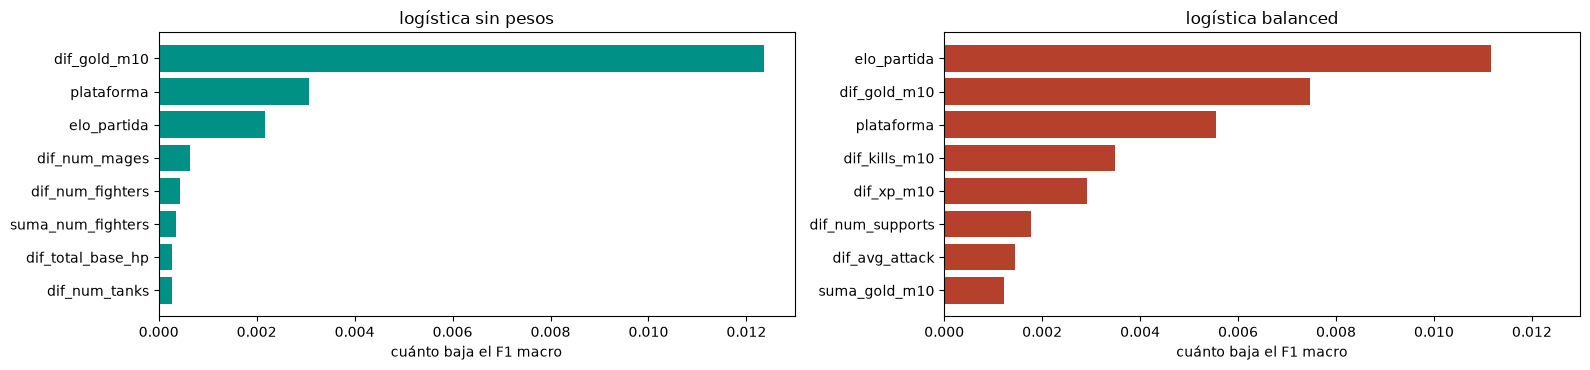

,logística sin pesos,logística balanced
dif_gold_m10,0.0124,0.0075
plataforma,0.0031,0.0055
elo_partida,0.0022,0.0112
dif_num_mages,0.0006,0.0011
dif_num_fighters,0.0004,-0.0022
suma_num_fighters,0.0004,-0.0019
dif_total_base_hp,0.0003,-0.0022
dif_num_tanks,0.0003,-0.0026


In [18]:
# 6.2 · La importancia por permutación en el test: cuánto baja el F1 macro al desordenar cada columna derivada
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), sharex=True)
importancia = {}
for ax, (n, m), color in zip(axes, modelos.items(), [TEAL, LADRILLO]):
    Z = m["derivar"].transform(X10_te)
    pi = permutation_importance(m[1:], Z, yb_te, scoring="f1_macro", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
    importancia[n] = pd.Series(pi.importances_mean, index=Z.columns)
    top = importancia[n].sort_values().tail(8)
    ax.barh(top.index, top, color=color)
    ax.set_title(n)
    ax.set_xlabel("cuánto baja el F1 macro")
plt.tight_layout()
plt.show()
pd.DataFrame(importancia).sort_values("logística sin pesos", ascending=False).head(8).round(4)

**Qué empuja hacia las bandas cortas y largas.** Los coeficientes de la sin pesos
cuentan lo mismo que la Entrega 3, ahora banda por banda:

- **`elo_partida`** baja de **+0,57** en `15-18` a **−0,76** en `45+`: a más elo, partidas
  más cortas.
- **`dif_gold_m10`**, la diferencia de oro al minuto 10, es **+0,43** en `15-18` y llega a
  **−0,29** en las bandas largas: un equipo que ya se separó cierra rápido. Es lo que
  afirmaba H9, y explica la banda de la rendición.
- Las curvas zigzaguean en `<15`, `42-45` y `45+`: son bandas con pocas partidas, y sus
  coeficientes se estiman con poco. Se lee la tendencia, no cada punto.

**La permutación lo confirma.** Para la sin pesos, la que más pesa es **`dif_gold_m10`**:
desordenarla baja el F1 macro en 0,012, un 12 % de su valor. Después vienen la
plataforma (0,003) y el elo (0,002). El resto no llega a 0,001.

# Sección 7 · El MSE y el R², en corto

El docente pidió probar el MSE y expresar bien el R². Son métricas de regresión: se
calculan sobre una predicción en segundos, así que se miden sobre el modelo de la
Entrega 3, `Ridge(alpha=100)`, con las mismas columnas y el mismo test.

In [19]:
ridge = armar(Ridge(alpha=100)).fit(X10, y10)
pr = ridge.predict(X10_te)
varianza = ((y10_te - y10_te.mean()) ** 2).mean()
mse = mean_squared_error(y10_te, pr)
pd.Series({"MAE (s)": mean_absolute_error(y10_te, pr), "MSE (s²)": mse, "RMSE (s)": np.sqrt(mse),
           "varianza de lo real (s²)": varianza, "1 − MSE / varianza": 1 - mse / varianza,
           "R² (r2_score)": r2_score(y10_te, pr)}).round(3)

MAE (s)                        294.679
MSE (s²)                    144081.971
RMSE (s)                       379.581
varianza de lo real (s²)    165425.591
1 − MSE / varianza               0.129
R² (r2_score)                    0.129
dtype: float64

**El R² es 1 − MSE / varianza.** La varianza de la duración real en el test es
165.426 s²: es el error cuadrático de contestar siempre el promedio. La regresión de la
E3 tiene un MSE de 144.082 s², el 87,1 % de eso. Lo que se saca de encima, el
**12,9 %**, es el R² de 0,129. **No es un porcentaje de partidas acertadas**: es cuánto
baja el error cuadrático respecto del promedio.

**El MSE eleva los errores al cuadrado**, así que castiga más los errores grandes y se
mide en segundos². Su raíz, el **RMSE**, vuelve a segundos: 379,6, contra un MAE de
294,7. Que el RMSE supere al MAE dice que hay errores grandes que pesan.

**Con la clasificación, estas métricas no aplican**: el modelo contesta una banda, no
un número de segundos. Lo que cumple su función es el error en minutos de la Sección 3
y la calibración de la Sección 5.

# Sección 8 · Cierre

In [20]:
# La tabla que resume, sobre el mismo test
pd.concat([tabla[["C", "F1 macro cv", "desvío F1"]], test.drop(columns="error ≤ 5 min")], axis=1).round(3)

,C,F1 macro cv,desvío F1,F1 macro,accuracy,±1 banda,error ≤ 3 min,error medio (min)
piso (banda más frecuente),NaN,0.026,0.001,0.025,0.179,0.522,0.37,5.326
logística sin pesos,1.0,0.106,0.005,0.099,0.197,0.525,0.38,5.261
logística balanced,0.1,0.101,0.008,0.096,0.101,0.277,0.18,10.071


**El modelo final es la regresión logística sin pesos, con `C=1`** (decisión del grupo:
la más simple, y la que da probabilidades por banda). Entre las dos versiones, la regla
de la cátedra elige la sin pesos: `balanced` no le gana en F1 macro y pierde en todo lo
demás.

**Qué tan bien funciona, sin adornarlo:**

- **Como clasificador puro, apenas le gana al piso.** F1 macro 0,099 contra 0,025,
  pero accuracy 19,7 % contra 17,9 %, y en minutos, 38,0 % de partidas a menos de 3
  minutos contra 37,0 %.
- **Lo que aporta son las probabilidades.** Están calibradas (dice 56 %, pasa 56 %) y
  cambian de partida en partida: en una de cada cuatro partidas dice 60 % o más para su
  ventana de 9 minutos, y acierta el 62 %.
- **Lo que mira** es la diferencia de oro al minuto 10 y el elo de la partida. La única
  banda que ve venir es `15-18`, la de la rendición.

**Para el jugador**, la salida no es una banda sola sino una frase como **«62 % de que
termine entre los 24 y los 33 minutos»**, una frase que hay que poder respaldar. Las
probabilidades calibradas son lo que la respalda.